# Expert-CFG 베이스라인 재현 — VQA-RAD

논문: *Uncertainty-Driven Expert Control: Enhancing the Reliability of Medical Vision-Language Models* (arXiv:2507.09209)

**재현 목표 (Table 1, Phi3.5V-Med 4.2B, VQA-RAD)**

| Open (recall) | Closed (acc) | Overall |
|---|---|---|
| 69.27 | 90.44 | 82.04 |

VQA-RAD: test 451 (open 179 / closed 272) — PathVQA 보다 훨씬 작아 빠른 검증에 적합합니다.

In [34]:
!git clone https://github.com/Minseongkim-dev/Expert-CFG.git /content/Expert-CFG 2>/dev/null || \
    (cd /content/Expert-CFG && git pull)

Already up to date.


In [5]:
from google.colab import drive
drive.mount('/content/drive')

OUTPUT_DIR  = '/content/drive/MyDrive/expert_cfg/logs_phi35_vqarad_baseline'
RESULT_JSON = '/content/drive/MyDrive/expert_cfg/vqarad_baseline_test.json'

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [6]:
# peft 0.21+ 는 torchao>=0.16.0 을 요구합니다
import importlib, subprocess, sys

def _pkg_version(name):
    try:
        return importlib.metadata.version(name)
    except importlib.metadata.PackageNotFoundError:
        return None

_torchao_ver = _pkg_version('torchao')
if _torchao_ver is None or tuple(int(x) for x in _torchao_ver.split('.')[:2]) < (0, 16):
    print(f'torchao {_torchao_ver} → 업그레이드 중...')
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'torchao>=0.16.0'])
    print('완료 (런타임 재시작 불필요)')
else:
    print(f'torchao {_torchao_ver} OK')

torchao 0.10.0 → 업그레이드 중...
완료 (런타임 재시작 불필요)


In [18]:
import os, sys, json, glob, random
from pathlib import Path

import numpy as np
import torch

def find_repo_root():
    for start in [Path("/content/Expert-CFG"), Path.cwd()]:
        if start.exists() and (start / "src" / "highlighter_modules").is_dir():
            return start.resolve()
    for parent in [Path.cwd().resolve(), *Path.cwd().resolve().parents]:
        if (parent / "src" / "highlighter_modules").is_dir():
            return parent
    raise FileNotFoundError("repo root 를 찾지 못했습니다. /content/Expert-CFG 에 clone 하세요.")

REPO_ROOT = find_repo_root()
os.chdir(REPO_ROOT)
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

import transformers, peft

USE_BF16 = torch.cuda.is_available() and torch.cuda.is_bf16_supported()
DEVICE    = "cuda" if torch.cuda.is_available() else "cpu"

print("repo         :", REPO_ROOT)
print("python       :", sys.version.split()[0])
print("torch        :", torch.__version__)
print("transformers :", transformers.__version__)
print("peft         :", peft.__version__)
if torch.cuda.is_available():
    print("GPU          :", torch.cuda.get_device_name(0))
    print("BF16         :", USE_BF16)

repo         : /content/Expert-CFG
python       : 3.13.16
torch        : 2.11.0+cu130
transformers : 5.20.2
peft         : 0.21.2
GPU          : NVIDIA A100-SXM4-40GB
BF16         : True


In [9]:
# ── 경로 ────────────────────────────────────────────────────────────────
BASE_MODEL_DIR = './Phi-3.5-vision-instruct'
MED_LORA_DIR   = './lora_weights/logs_phi35_pubmed_instruct'
MED_LORA_HF    = 'ecoxial2007/Phi-3.5V-Med'
VQARAD_DIR     = './data/VQA_RAD'

# ── LoRA (논문 §4.3) ─────────────────────────────────────────────────────
LORA_RANK        = 64
LORA_ALPHA_RATIO = 2
LORA_DROPOUT     = 0.0
LORA_TARGET      = ['qkv_proj', 'o_proj', 'gate_up_proj', 'down_proj']
FREEZE_VISION    = True

# ── 학습 (§4.3) ──────────────────────────────────────────────────────────
LR            = 1e-4
GLOBAL_BATCH  = 64
EPOCHS        = 5
PER_DEVICE_BS = 1
WORLD_SIZE    = int(os.environ.get('WORLD_SIZE', 1))
GRAD_ACCUM    = GLOBAL_BATCH // (PER_DEVICE_BS * WORLD_SIZE)
WARMUP_RATIO  = 0.03
WEIGHT_DECAY  = 0.0

# ── 추론/학습 이미지 크롭 ─────────────────────────────────────────────────
# 논문은 16크롭이지만 T4(16GB)에서는 OOM → 4로 줄임
# A100 사용 시 16으로 변경 가능
_gpu_name = torch.cuda.get_device_name(0).lower() if torch.cuda.is_available() else ''
NUM_CROPS = 16
print(f'NUM_CROPS={NUM_CROPS}  (GPU: {_gpu_name or "cpu"})')

# T4는 BF16 네이티브 미지원 → FP16 사용
USE_BF16 = torch.cuda.is_available() and 'a100' in _gpu_name
USE_FP16 = torch.cuda.is_available() and not USE_BF16
print(f'precision: {"bf16" if USE_BF16 else "fp16" if USE_FP16 else "fp32"}')

# ── 추론 ─────────────────────────────────────────────────────────────────
MAX_NEW_TOKENS = 64
NUM_BEAMS      = 1
SEED = 42

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
os.makedirs(OUTPUT_DIR, exist_ok=True)
os.makedirs(os.path.dirname(RESULT_JSON), exist_ok=True)
print(f'grad_accum={GRAD_ACCUM}  (global batch {GLOBAL_BATCH})')
print(f'OUTPUT_DIR = {OUTPUT_DIR}')

NUM_CROPS=16  (GPU: nvidia a100-sxm4-40gb)
precision: bf16
grad_accum=64  (global batch 64)
OUTPUT_DIR = /content/drive/MyDrive/expert_cfg/logs_phi35_vqarad_baseline


In [ ]:
# ── transformers 5.x 호환: Phi3VForCausalLM._attn_implementation 패치 ──
# transformers 5.x 는 from_pretrained() 에서 _attn_implementation 을 모델 __init__ 에
# 직접 kwarg 로 넘기는 코드 경로가 있음 — 커스텀 모델이 **kwargs 를 받지 않으면 TypeError.
import os, re

_mfile = os.path.join(BASE_MODEL_DIR, 'modeling_phi3_v.py')
if os.path.exists(_mfile):
    with open(_mfile) as _f:
        _src = _f.read()

    # def __init__(self, config: Phi3VConfig): → ... **kwargs):
    _patterns = [
        ('def __init__(self, config: Phi3VConfig):',  'def __init__(self, config: Phi3VConfig, **kwargs):'),
        ('def __init__(self, config: PretrainedConfig):', 'def __init__(self, config: PretrainedConfig, **kwargs):'),
    ]
    _patched = _src
    for _old, _new in _patterns:
        _patched = _patched.replace(_old, _new)

    if _patched == _src:
        # 정확한 타입 힌트가 다를 경우를 대비한 정규식 폴백
        _patched = re.sub(
            r'(def __init__\(self, config[^)]*?)(\):)',
            lambda m: m.group(0) if '**kwargs' in m.group(0) else m.group(1) + ', **kwargs' + m.group(2),
            _src
        )

    if _patched != _src:
        with open(_mfile, 'w') as _f:
            _f.write(_patched)
        print('modeling_phi3_v.py 패치 완료 (_attn_implementation **kwargs 추가)')
    else:
        print('modeling_phi3_v.py 이미 패치됨 / 패턴 미발견')
else:
    print(f'파일 없음: {_mfile}  (다운로드 후 실행하세요)')


In [10]:
# ── 진단 셀 ──
import os
_base = '/content/drive/MyDrive/vqa_rad'
if not os.path.exists(_base):
    print('❌ 폴더 없음:', _base)
else:
    for _item in sorted(os.listdir(_base)):
        _p = os.path.join(_base, _item)
        _sz = len(os.listdir(_p)) if os.path.isdir(_p) else os.path.getsize(_p)
        print(f'{"[DIR]" if os.path.isdir(_p) else "[FILE]"} {_item}  ({_sz})')


[FILE] VQA_RAD Dataset Public.json  (1419295)
[DIR] VQA_RAD Image Folder  (315)


In [11]:
import shutil, os
shutil.rmtree('./data/VQA_RAD', ignore_errors=True)


In [24]:
import subprocess
from PIL import Image
from datasets import load_dataset

# ── Google Drive 업로드 경로 ───────────────────────────────────────────
_GDRIVE_JSON   = '/content/drive/MyDrive/vqa_rad/VQA_RAD Dataset Public.json'
_GDRIVE_IMGDIR = '/content/drive/MyDrive/vqa_rad/VQA_RAD Image Folder'

def answer_type_of(ans):
    return 'CLOSED' if str(ans).strip().lower() in ('yes', 'no') else 'OPEN'

def _prepare_local():
    train_json = os.path.join(VQARAD_DIR, 'train.json')
    test_json  = os.path.join(VQARAD_DIR, 'test.json')
    if os.path.exists(train_json) and os.path.exists(test_json):
        print('로컬 train/test JSON 이미 존재 → 재사용')
        return True

    raw_candidates = [
        _GDRIVE_JSON,
        os.path.join(VQARAD_DIR, 'VQA_RAD Dataset Public.json'),
        os.path.join(VQARAD_DIR, 'VQA_RAD_Dataset_Public.json'),
    ]
    raw_json = None
    for _p in raw_candidates:
        if os.path.exists(_p):
            _sz = os.path.getsize(_p)
            if _sz > 0:
                raw_json = _p
                print(f'원본 JSON 발견: {_p}  ({_sz:,} bytes)')
                break
            else:
                print(f'파일 비어있음(0 bytes): {_p}')

    if raw_json is None:
        os.makedirs(VQARAD_DIR, exist_ok=True)
        _osf_dst = os.path.join(VQARAD_DIR, 'VQA_RAD_Dataset_Public.json')
        print('OSF에서 VQA-RAD 원본 다운로드 중...')
        try:
            r = subprocess.run(
                ['wget', '-q', '-O', _osf_dst, 'https://osf.io/download/9dpze/'],
                timeout=120, capture_output=True)
            if r.returncode == 0 and os.path.getsize(_osf_dst) > 0:
                raw_json = _osf_dst
            else:
                return False
        except Exception as e:
            print(f'  OSF 다운로드 실패: {e}')
            return False

    with open(raw_json) as f:
        all_data = json.load(f)

    # answer_type 정규화
    for item in all_data:
        if 'answer_type' not in item:
            item['answer_type'] = answer_type_of(item.get('answer', ''))
        else:
            item['answer_type'] = item['answer_type'].upper()

    # ── phrase_type 기반 split ──────────────────────────────────────
    # README §5: test = test_freeform(300) + test_paraphrase(151) = 451
    #            train = freeform + para
    _TEST_TYPES = {'test_freeform', 'test_para'}
    _phrase_vals = {str(r.get('phrase_type', '')).lower() for r in all_data}
    print(f'phrase_type 고유값: {_phrase_vals}')

    if _TEST_TYPES & _phrase_vals:
        test_data  = [r for r in all_data if str(r.get('phrase_type','')).lower() in _TEST_TYPES]
        train_data = [r for r in all_data if str(r.get('phrase_type','')).lower() not in _TEST_TYPES]
    elif 'para' in _phrase_vals:
        # 구버전 JSON: freeform/para 만 있을 때 — para 를 test 로 쓰면 안 되므로
        # 뒤 451 개를 test 로 fallback
        print('경고: test_freeform/test_paraphrase 없음 → 뒤 451개를 test로 사용')
        test_data  = all_data[-451:]
        train_data = all_data[:-451]
    else:
        test_data  = all_data[-451:]
        train_data = all_data[:-451]

    os.makedirs(VQARAD_DIR, exist_ok=True)
    with open(train_json, 'w') as f: json.dump(train_data, f)
    with open(test_json,  'w') as f: json.dump(test_data,  f)
    print(f'분리 완료: train={len(train_data)}, test={len(test_data)}')
    print(f'  test closed={sum(1 for r in test_data if r["answer_type"]=="CLOSED")}, '
          f'open={sum(1 for r in test_data if r["answer_type"]=="OPEN")}')
    return True

def _find_img_root():
    for p in [_GDRIVE_IMGDIR,
              os.path.join(VQARAD_DIR, 'VQA_RAD Image Folder'),
              os.path.join(VQARAD_DIR, 'images')]:
        if os.path.isdir(p):
            return p
    return os.path.join(VQARAD_DIR, 'images')

_HF_CANDIDATES = {
    'train': [('flaviagiammarino/vqa-rad', 'train')],
    'test':  [('flaviagiammarino/vqa-rad', 'test')],
}

def _try_load_hf(split, cache_dir):
    for ds_id, sp in _HF_CANDIDATES[split]:
        try:
            ds = load_dataset(ds_id, split=sp, cache_dir=cache_dir)
            print(f'  HF 로드: {ds_id}/{sp}  ({len(ds)})')
            return ds, ds_id
        except Exception as e:
            print(f'  {ds_id}/{sp} 실패: {type(e).__name__}')
    raise RuntimeError('VQA-RAD 데이터를 가져오지 못했습니다.')

class VQARADSplit(torch.utils.data.Dataset):
    def __init__(self, split):
        local_json = os.path.join(VQARAD_DIR, f'{split}.json')
        if os.path.exists(local_json):
            with open(local_json) as f:
                self.records = json.load(f)
            self.source   = 'local'
            self.img_root = _find_img_root()
            self.ds_id    = 'local'
            print(f'[{split}] 로컬 JSON ({len(self.records)}개), 이미지: {self.img_root}')
        else:
            print(f'[{split}] HuggingFace 로드...')
            hf_ds, self.ds_id = _try_load_hf(split, os.path.join(VQARAD_DIR, 'hf_cache'))
            self.records = hf_ds
            self.source  = 'hf'

    def __len__(self):
        return len(self.records)

    def __getitem__(self, idx):
        r = self.records[idx]
        if self.source == 'local':
            img_name = (r.get('image_name') or r.get('img_name')
                        or r.get('image') or r.get('img_id', ''))
            image = Image.open(os.path.join(self.img_root, img_name)).convert('RGB')
            q  = str(r.get('question', '')).strip()
            a  = str(r.get('answer',   '')).strip()
            at = str(r.get('answer_type', '')).upper()
            if at not in ('OPEN', 'CLOSED'):
                at = answer_type_of(a)
        else:
            q   = str(r.get('question') or '').strip()
            a   = str(r.get('answer')   or '').strip()
            img = r.get('image') or r.get('img')
            image = img.convert('RGB') if img else Image.new('RGB', (224, 224))
            at  = str(r.get('answer_type', '')).upper()
            if at not in ('OPEN', 'CLOSED'):
                at = answer_type_of(a)
        return {'image': image, 'question': q, 'answer': a, 'answer_type': at}

def type_counts(ds):
    c = {'OPEN': 0, 'CLOSED': 0}
    for i in range(len(ds)):
        c[ds[i]['answer_type']] += 1
    return c['CLOSED'], c['OPEN']

# ── 실행 ─────────────────────────────────────────────────────────────
_ok = _prepare_local()
if not _ok:
    print('경고: 로컬 JSON 준비 실패 → HuggingFace 폴백')

train_ds = VQARADSplit('train')
test_ds  = VQARADSplit('test')

for name, ds in [('train', train_ds), ('test', test_ds)]:
    c, o = type_counts(ds)
    print(f'{name:5s} [{ds.ds_id}] total={len(ds):4d}  closed={c:3d}  open={o:3d}')
print('논문 기준: test total=451')

로컬 train/test JSON 이미 존재 → 재사용
[train] 로컬 JSON (1797개), 이미지: /content/drive/MyDrive/vqa_rad/VQA_RAD Image Folder
[test] 로컬 JSON (451개), 이미지: /content/drive/MyDrive/vqa_rad/VQA_RAD Image Folder
train [local] total=1797  closed=1026  open=771
test  [local] total= 451  closed=272  open=179
논문 기준: test total=451


In [22]:
import shutil
from huggingface_hub import snapshot_download
from transformers import AutoModelForCausalLM, AutoProcessor, GenerationConfig
from peft import PeftModel, LoraConfig, get_peft_model

_SKIP_FILES = {'processor_config.json', 'processing_phi3_v_cfg.py'}

# 1) 기본 가중치 다운로드
if not os.path.exists(os.path.join(BASE_MODEL_DIR, 'config.json')):
    print('Phi-3.5-vision-instruct 가중치 다운로드 중 (~8 GB)...')
    _hf_tmp = snapshot_download('microsoft/Phi-3.5-vision-instruct',
                                local_dir='/tmp/phi35_hf',
                                ignore_patterns=['*.git', '__pycache__'])
    os.makedirs(BASE_MODEL_DIR, exist_ok=True)
    for _f in os.listdir(_hf_tmp):
        if _f in _SKIP_FILES:
            continue
        _s, _d = os.path.join(_hf_tmp, _f), os.path.join(BASE_MODEL_DIR, _f)
        (shutil.copytree if os.path.isdir(_s) else shutil.copy2)(
            _s, _d, **({'dirs_exist_ok': True} if os.path.isdir(_s) else {}))
    print('완료')
else:
    print('기본 가중치 이미 존재')

with open(os.path.join(BASE_MODEL_DIR, 'processor_config.json')) as _f:
    assert 'processing_phi3_v_cfg' in _f.read(), \
        'processor_config.json 이 HF 원본으로 덮어써졌습니다 — repo 버전으로 복원하세요'

processor = AutoProcessor.from_pretrained(BASE_MODEL_DIR, trust_remote_code=True, num_crops=NUM_CROPS)

# 2) Med LoRA 다운로드/확인
def resolve_med_lora():
    if os.path.exists(os.path.join(MED_LORA_DIR, 'adapter_config.json')):
        return MED_LORA_DIR
    local = snapshot_download(MED_LORA_HF, local_dir='./lora_weights/Phi-3.5V-Med')
    found = glob.glob(os.path.join(local, '**', 'adapter_config.json'), recursive=True)
    assert found, f'{MED_LORA_HF} 에서 adapter_config.json 을 찾지 못했습니다'
    return os.path.dirname(found[0])

med_lora_path = resolve_med_lora()
print('Med LoRA :', med_lora_path)

# 3) Base → Med LoRA merge → 새 downstream LoRA 추가 (fine-tuning 준비)
_model_dtype = torch.bfloat16 if USE_BF16 else torch.float16
print(f'모델 로드 dtype: {_model_dtype}')

base = AutoModelForCausalLM.from_pretrained(
    BASE_MODEL_DIR, dtype=_model_dtype,
    trust_remote_code=True, _attn_implementation='eager')

model = PeftModel.from_pretrained(base, med_lora_path).merge_and_unload()

model = get_peft_model(model, LoraConfig(
    r=LORA_RANK, lora_alpha=LORA_RANK * LORA_ALPHA_RATIO,
    lora_dropout=LORA_DROPOUT, target_modules=LORA_TARGET,
    init_lora_weights=True, task_type='CAUSAL_LM'))

if FREEZE_VISION:
    for n, p in model.named_parameters():
        if 'vision_embed_tokens' in n:
            p.requires_grad_(False)

# transformers 5.x + PEFT: merge_and_unload() 후 generation_config 가 유실되는 버그 대응
try:
    _gen_cfg = GenerationConfig.from_pretrained(BASE_MODEL_DIR)
except Exception:
    _gen_cfg = GenerationConfig()
model.generation_config = _gen_cfg

model.print_trainable_parameters()
model.to(DEVICE)
print('모델 준비 완료 (fine-tuning 준비 상태)')

Phi-3.5-vision-instruct 가중치 다운로드 중 (~8 GB)...


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 21 files:   0%|          | 0/21 [00:00<?, ?it/s]

[transformers] `Phi3VProcessor` defines `image_processor_class = 'Phi3VImageProcessor'`, which is deprecated. Register the correct mapping in `AutoImageProcessor` instead.
[transformers] Image processor Phi3VImageProcessor: kwargs ['num_crops'] were applied for backward compatibility. To avoid this warning, add them to valid_kwargs: create a custom TypedDict extending ImagesKwargs with these keys and set it as the `valid_kwargs` class attribute.
[transformers] Missing validation function in 'RotaryEmbeddingConfigMixin' for 'rope_type'='su'


...

Fetching 14 files:   0%|          | 0/14 [00:00<?, ?it/s]

[transformers] Missing validation function in 'RotaryEmbeddingConfigMixin' for 'rope_type'='su'


Med LoRA : /content/Expert-CFG/lora_weights/Phi-3.5V-Med
모델 로드 dtype: torch.bfloat16


Loading weights:   0%|          | 0/592 [00:00<?, ?it/s]

trainable params: 100,663,296 || all params: 4,247,284,736 || trainable%: 2.3701
모델 준비 완료 (fine-tuning 준비 상태)


In [25]:
from transformers import Trainer, TrainingArguments
import inspect, re
from collections import Counter
from tqdm.auto import tqdm

# ── 평가 함수 ─────────────────────────────────────────────────────────
def normalize(text):
    text = text.lower().replace('<|end|>', ' ')
    return re.sub(r'[^a-z0-9\s]', ' ', text).split()

def closed_accuracy(pred, gt):
    return float(gt.strip().lower() in normalize(pred))

def open_recall(pred, gt):
    gt_toks, pred_toks = Counter(normalize(gt)), Counter(normalize(pred))
    if not gt_toks:
        return 0.0
    return sum((gt_toks & pred_toks).values()) / sum(gt_toks.values())

def predictive_entropy(step_scores):
    if not step_scores:
        return 0.0
    logits = torch.stack([s[0] for s in step_scores]).float()
    logp = torch.log_softmax(logits, dim=-1)
    return (-(logp.exp() * logp).sum(-1)).mean().item()

@torch.no_grad()
def evaluate(model, processor, dataset, max_samples=None):
    model.eval()
    end_id = processor.tokenizer.convert_tokens_to_ids('<|end|>')
    records = []
    n = len(dataset) if max_samples is None else min(max_samples, len(dataset))
    for i in tqdm(range(n)):
        ex = dataset[i]
        prompt = processor.tokenizer.apply_chat_template(
            [{'role': 'user', 'content': f"<|image_1|>\n{ex['question']}"}],
            tokenize=False, add_generation_prompt=True)
        inputs = processor(prompt, [ex['image']], return_tensors='pt', qs_highlighted_parts=[])
        del inputs['highlight_attention_mask']
        inputs = {k: v.to(DEVICE) for k, v in inputs.items()}
        out = model.generate(
            **inputs,
            max_new_tokens=MAX_NEW_TOKENS, num_beams=NUM_BEAMS, do_sample=False,
            eos_token_id=[processor.tokenizer.eos_token_id, end_id],
            output_scores=True, return_dict_in_generate=True,
            use_cache=False,  # KV 캐시 비활성화 (transformers 5.x 캐시 호환성 문제 우회)
        )
        gen_ids = out.sequences[:, inputs['input_ids'].size(1):]
        pred = processor.batch_decode(gen_ids, skip_special_tokens=True,
                                      clean_up_tokenization_spaces=False)[0].strip().strip('.')
        score = (closed_accuracy if ex['answer_type'] == 'CLOSED' else open_recall)(pred, ex['answer'])
        records.append({'idx': i, 'question': ex['question'], 'answer': ex['answer'],
                        'answer_type': ex['answer_type'], 'prediction': pred,
                        'score': score, 'entropy': predictive_entropy(out.scores)})
    return records

def summarize(records):
    closed = [r['score'] for r in records if r['answer_type'] == 'CLOSED']
    opened = [r['score'] for r in records if r['answer_type'] == 'OPEN']
    return {'open':    100 * np.mean(opened)  if opened  else float('nan'),
            'closed':  100 * np.mean(closed)  if closed  else float('nan'),
            'overall': 100 * np.mean([r['score'] for r in records]),
            'n_open': len(opened), 'n_closed': len(closed)}

# ── collator ──────────────────────────────────────────────────────────
class VQARADCollator:
    def __init__(self, processor):
        self.processor = processor
    def __call__(self, examples):
        assert len(examples) == 1
        ex = examples[0]
        prompt = self.processor.tokenizer.apply_chat_template(
            [{'role': 'user', 'content': f"<|image_1|>\n{ex['question']}"}],
            tokenize=False, add_generation_prompt=True)
        answer = f"{ex['answer']}<|end|>\n<|endoftext|>"
        batch = self.processor(prompt, [ex['image']], return_tensors='pt', qs_highlighted_parts=[])
        del batch['highlight_attention_mask']
        prompt_ids = batch['input_ids']
        answer_ids = self.processor.tokenizer(answer, add_special_tokens=False, return_tensors='pt')['input_ids']
        batch['input_ids'] = torch.cat([prompt_ids, answer_ids], dim=1)
        batch['labels']    = torch.cat([torch.full_like(prompt_ids, -100), answer_ids], dim=1)
        del batch['attention_mask']
        return batch

print('평가/학습 함수 정의 완료')

평가/학습 함수 정의 완료


In [16]:
# ── VQA-RAD Downstream Fine-tuning ───────────────────────────────────
_ta_params = set(inspect.signature(TrainingArguments.__init__).parameters)
_total_steps = (len(train_ds) * EPOCHS + GRAD_ACCUM - 1) // GRAD_ACCUM
_v4 = dict(learning_rate=LR, optim='adamw_torch', lr_scheduler_type='cosine', weight_decay=WEIGHT_DECAY)
if 'warmup_ratio' in _ta_params:
    _v4['warmup_ratio'] = WARMUP_RATIO
elif 'warmup_steps' in _ta_params:
    _v4['warmup_steps'] = int(_total_steps * WARMUP_RATIO)
    print(f'warmup_steps={_v4["warmup_steps"]}')

training_args = TrainingArguments(
    output_dir=OUTPUT_DIR,
    num_train_epochs=EPOCHS,
    per_device_train_batch_size=PER_DEVICE_BS,
    gradient_accumulation_steps=GRAD_ACCUM,
    bf16=USE_BF16,
    fp16=USE_FP16,
    gradient_checkpointing=True,
    gradient_checkpointing_kwargs={'use_reentrant': False},
    logging_steps=10,
    save_strategy='epoch',
    save_total_limit=2,
    save_only_model=True,
    remove_unused_columns=False,
    dataloader_num_workers=0,
    report_to='none',
    seed=SEED,
    **{k: v for k, v in _v4.items() if k in _ta_params},
)

trainer = Trainer(model=model, args=training_args,
                  train_dataset=train_ds, data_collator=VQARADCollator(processor))

_ckpt_dirs = sorted(glob.glob(os.path.join(OUTPUT_DIR, 'checkpoint-*')))
_resume = _ckpt_dirs[-1] if _ckpt_dirs else False
print(f'resume_from_checkpoint = {_resume}')

trainer.train(resume_from_checkpoint=_resume)
trainer.save_model(OUTPUT_DIR)
print('학습 완료')

warmup_steps=4
resume_from_checkpoint = /content/drive/MyDrive/expert_cfg/logs_phi35_vqarad_baseline/checkpoint-87


[transformers] `use_return_dict` is deprecated! Use `return_dict` instead!
/usr/local/lib/python3.13/dist-packages/transformers/modeling_attn_mask_utils.py:71: FutureWarning: The attention mask API under `transformers.modeling_attn_mask_utils` (`AttentionMaskConverter`) is deprecated and will be removed in Transformers v5.10. Please use the new API in `transformers.masking_utils`.
  warnings.warn(DEPRECATION_MESSAGE, FutureWarning)
/usr/local/lib/python3.13/dist-packages/transformers/modeling_attn_mask_utils.py:172: FutureWarning: The attention mask API under `transformers.modeling_attn_mask_utils` (`AttentionMaskConverter`) is deprecated and will be removed in Transformers v5.10. Please use the new API in `transformers.masking_utils`.
  warnings.warn(DEPRECATION_MESSAGE, FutureWarning)


Step,Training Loss
90,0.137259
100,0.115164
110,0.151752
120,0.127272
130,0.060215
140,0.052099


[transformers] Missing validation function in 'RotaryEmbeddingConfigMixin' for 'rope_type'='su'
[transformers] Missing validation function in 'RotaryEmbeddingConfigMixin' for 'rope_type'='su'
[transformers] Missing validation function in 'RotaryEmbeddingConfigMixin' for 'rope_type'='su'


학습 완료


In [28]:
# downstream LoRA 어댑터 비활성화
model.disable_adapter_layers()

records_med = evaluate(model, processor, test_ds, max_samples=50)
m_med = summarize(records_med)
print(f"Med LoRA only (50개):  open={m_med['open']:.1f}  closed={m_med['closed']:.1f}  overall={m_med['overall']:.1f}")

# 다시 활성화
model.enable_adapter_layers()


  0%|          | 0/50 [00:00<?, ?it/s]

KeyboardInterrupt: 

In [ ]:
from transformers import AutoModelForCausalLM, GenerationConfig
from peft import PeftModel

_dtype = torch.bfloat16 if USE_BF16 else torch.float16

base = AutoModelForCausalLM.from_pretrained(
    BASE_MODEL_DIR,
    dtype=_dtype,
    trust_remote_code=True,
    _attn_implementation='eager')

model_med_only = PeftModel.from_pretrained(base, med_lora_path).merge_and_unload()
try:
    model_med_only.generation_config = GenerationConfig.from_pretrained(BASE_MODEL_DIR)
except Exception:
    model_med_only.generation_config = GenerationConfig()
model_med_only = model_med_only.to(DEVICE).eval()
print('Med-only 모델 로드 완료')


In [31]:
from transformers import GenerationConfig
try:
    model.generation_config = GenerationConfig.from_pretrained(BASE_MODEL_DIR)
except Exception:
    model.generation_config = GenerationConfig()


In [30]:
# transformers 5.x 호환성 패치
from transformers import GenerationMixin
from transformers.cache_utils import DynamicCache

# 1) Phi3VForCausalLM 에 generate() 메서드 추가
_cls = type(model.base_model.model)
if not issubclass(_cls, GenerationMixin):
    _cls.__bases__ = (GenerationMixin,) + _cls.__bases__
    print(f'Patched {_cls.__name__} with GenerationMixin')

# 2) DynamicCache.seen_tokens 속성 복원 (transformers 5.x 에서 삭제됨)
if not hasattr(DynamicCache, 'seen_tokens'):
    DynamicCache.seen_tokens = property(lambda self: self.get_seq_length())
    print('Patched DynamicCache.seen_tokens')

Patched Phi3VForCausalLM with GenerationMixin
Patched DynamicCache.seen_tokens


In [32]:
from transformers.cache_utils import DynamicCache

if not hasattr(DynamicCache, 'get_usable_length'):
    def _get_usable_length(self, new_seq_length, layer_idx=0):
        return self.get_seq_length(layer_idx)
    DynamicCache.get_usable_length = _get_usable_length
    print('Patched get_usable_length')

if not hasattr(DynamicCache, 'get_max_length'):
    DynamicCache.get_max_length = lambda self: None
    print('Patched get_max_length')


Patched get_usable_length


In [20]:
# ── 테스트셋 평가 ─────────────────────────────────────────────────────
records = evaluate(model, processor, test_ds)
with open(RESULT_JSON, 'w') as f:
    json.dump(records, f, indent=2, ensure_ascii=False)

m = summarize(records)
paper = {'open': 69.27, 'closed': 90.44, 'overall': 82.04}
print(f"{'':8s}{'paper':>8s}{'ours':>8s}{'diff':>8s}")
for k in ('open', 'closed', 'overall'):
    print(f'{k:8s}{paper[k]:8.2f}{m[k]:8.2f}{m[k]-paper[k]:+8.2f}')
print(f"n_open={m['n_open']}, n_closed={m['n_closed']}")
print(f'결과 저장: {RESULT_JSON}')

  0%|          | 0/451 [00:00<?, ?it/s]

           paper    ours    diff
open       69.27   33.46  -35.81
closed     90.44   72.06  -18.38
overall    82.04   56.74  -25.30
n_open=179, n_closed=272
결과 저장: /content/drive/MyDrive/expert_cfg/vqarad_baseline_test.json


In [25]:
from collections import Counter

# 모델 예측 분포
preds_closed = [r['prediction'].strip().lower()[:20] 
                for r in records if r['answer_type'] == 'CLOSED']
print('Closed 예측 분포 (상위 10):')
print(Counter(preds_closed).most_common(10))

# GT 분포
gts_closed = [r['answer'].strip().lower() 
              for r in records if r['answer_type'] == 'CLOSED']
print('\nClosed GT 분포:')
print(Counter(gts_closed).most_common(10))



Closed 예측 분포 (상위 10):
[('no', 139), ('yes', 111), ('left', 3), ('mri', 3), ('female', 2), ('bilateral', 2), ('normal', 2), ('multiple', 1), ('smaller', 1), ('supratentorial', 1)]

Closed GT 분포:
[('no', 133), ('yes', 118), ('mri', 3), ('abnormal', 3), ('left', 2), ('female', 2), ('one', 1), ('smaller', 1), ('supratentorial', 1), ('right', 1)]


In [30]:
# open 오답 10개 확인
open_wrong = [r for r in records if r['answer_type'] == 'OPEN' and r['score'] < 0.5]
for r in open_wrong[:10]:
    print(f"Q: {r['question']}")
    print(f"  GT: {r['answer']}  |  PRED: {r['prediction']}  |  score: {r['score']:.2f}")
    print()


Q: How is the patient oriented?
  GT: Posterior-Anterior  |  PRED: PA  |  score: 0.00

Q: Describe the lung abnormalities?
  GT: Pulmonary nodules  |  PRED: Bilateral pleural effusion  |  score: 0.00

Q: What abnormalities are seen within the lungs?
  GT: Pulmonary nodules  |  PRED: Bilateral pleural effusion  |  score: 0.00

Q: What is under the right hemidiaphragm?
  GT: Free air  |  PRED: The right half of the liver  |  score: 0.00

Q: What is the abnormality by the right hemidiaphragm?
  GT: Free air  |  PRED: pleural placement  |  score: 0.00

Q: How would you describe the spleen abnormality
  GT: hypodense lesion  |  PRED: Splenomegaly  |  score: 0.00

Q: What is abnormal about the spleen?
  GT: hypodense lesion  |  PRED: Splenomegaly  |  score: 0.00

Q: How many lesions are in the spleen?
  GT: one  |  PRED: 1  |  score: 0.00

Q: What is abnormal about the pancreas?
  GT: Enlarged  |  PRED: Nothing  |  score: 0.00

Q: Why is the pancreas abnormal?
  GT: Enlarged  |  PRED: fatty 

## 7. 불확실성 추정 검증 (Figure 3)

엔트로피로 오답(incorrect)을 판별하는 ROC-AUC. 이후 Expert-CFG 에서 상위 5% 고엔트로피 샘플을 선택할 때 그대로 사용합니다.
open 문항은 recall == 1 일 때 정답으로 간주 (논문 미명시).
PathVQA AUC = 0.91 (paper Figure 3); VQA-RAD AUC 는 논문에 별도 미기재.

AUC = 0.735  (PathVQA paper: 0.91 — VQA-RAD 미기재)
top-5% 고엔트로피 23개 중 오답 비율: 1.000
  CLOSED  AUC = 0.640  (n=272)
  OPEN    AUC = 0.750  (n=179)


/tmp/ipykernel_106564/2710560724.py:31: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axes[1].boxplot([ent[wrong == 0], ent[wrong == 1]], labels=['correct', 'incorrect'])


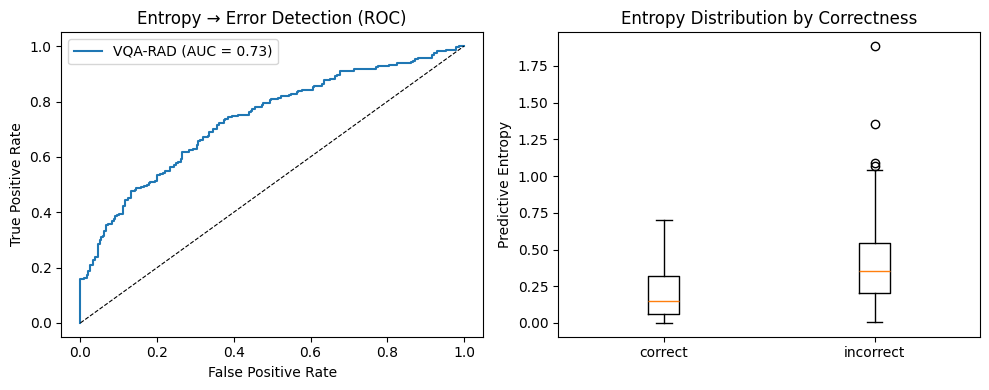

그래프 저장: /content/drive/MyDrive/expert_cfg/vqarad_uncertainty.png


In [21]:
from sklearn.metrics import roc_auc_score, roc_curve
import matplotlib.pyplot as plt

ent   = np.array([r['entropy'] for r in records])
wrong = np.array([0 if r['score'] == 1.0 else 1 for r in records])

auc = roc_auc_score(wrong, ent)
fpr, tpr, _ = roc_curve(wrong, ent)
print(f'AUC = {auc:.3f}  (PathVQA paper: 0.91 — VQA-RAD 미기재)')

top5 = np.argsort(-ent)[: int(round(0.05 * len(ent)))]
print(f'top-5% 고엔트로피 {len(top5)}개 중 오답 비율: {wrong[top5].mean():.3f}')

# ── 유형별 분리 AUC ────────────────────────────────────────────────────
for atype in ('CLOSED', 'OPEN'):
    idx = [i for i, r in enumerate(records) if r['answer_type'] == atype]
    if len(idx) > 1 and wrong[idx].sum() > 0:
        sub_auc = roc_auc_score(wrong[idx], ent[idx])
        print(f'  {atype:6s}  AUC = {sub_auc:.3f}  (n={len(idx)})')

# ── 시각화 ────────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

axes[0].plot(fpr, tpr, label=f'VQA-RAD (AUC = {auc:.2f})')
axes[0].plot([0, 1], [0, 1], 'k--', lw=0.8)
axes[0].set_xlabel('False Positive Rate')
axes[0].set_ylabel('True Positive Rate')
axes[0].set_title('Entropy → Error Detection (ROC)')
axes[0].legend()

axes[1].boxplot([ent[wrong == 0], ent[wrong == 1]], labels=['correct', 'incorrect'])
axes[1].set_ylabel('Predictive Entropy')
axes[1].set_title('Entropy Distribution by Correctness')

plt.tight_layout()
plt.savefig('/content/drive/MyDrive/expert_cfg/vqarad_uncertainty.png', dpi=150)
plt.show()
print('그래프 저장: /content/drive/MyDrive/expert_cfg/vqarad_uncertainty.png')

## 8. 저장된 체크포인트로 평가만 다시 하기

학습을 건너뛰고 `OUTPUT_DIR` 의 LoRA 로 평가할 때 사용 (모델 로드 셀 대신 실행).

In [35]:
def load_for_eval(adapter_dir=OUTPUT_DIR):
    from transformers import AutoModelForCausalLM, GenerationConfig
    from peft import PeftModel
    _dtype = torch.bfloat16 if USE_BF16 else torch.float16
    base = AutoModelForCausalLM.from_pretrained(
        BASE_MODEL_DIR, dtype=_dtype,
        trust_remote_code=True, _attn_implementation='eager')
    base = PeftModel.from_pretrained(base, resolve_med_lora()).merge_and_unload()
    m = PeftModel.from_pretrained(base, adapter_dir).to(DEVICE).eval()
    try:
        m.generation_config = GenerationConfig.from_pretrained(BASE_MODEL_DIR)
    except Exception:
        m.generation_config = GenerationConfig()
    return m

# 사용 예:
model = load_for_eval()
records = evaluate(model, processor, test_ds)
m = summarize(records); print(m)


[transformers] Missing validation function in 'RotaryEmbeddingConfigMixin' for 'rope_type'='su'


Loading weights:   0%|          | 0/592 [00:00<?, ?it/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 14 files:   0%|          | 0/14 [00:00<?, ?it/s]

  0%|          | 0/451 [00:00<?, ?it/s]

KeyboardInterrupt: 